# Three classic spatial derivatives; use of Bokeh; and vector operations

We will introduce the interactive plotting library Bokeh (for more on Bokeh, click [here](https://bokeh.pydata.org/en/latest/)).

In [2]:
# import numpy so that it is available
import numpy as np

# import the typical matplotlib stuff... we will only use if for one plot.
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display

# import Bokeh stuff and define the tools
from bokeh.io import output_notebook, show
from bokeh.plotting import figure
TOOLS = 'box_zoom,box_select,reset,hover,wheel_zoom'
output_notebook()

Loading BokehJS ...

## Define a function and plot in the standard way

Let's look at the function $f(x) = \sin(x)$ and plot it from 0 to $6\pi$ using 100 points

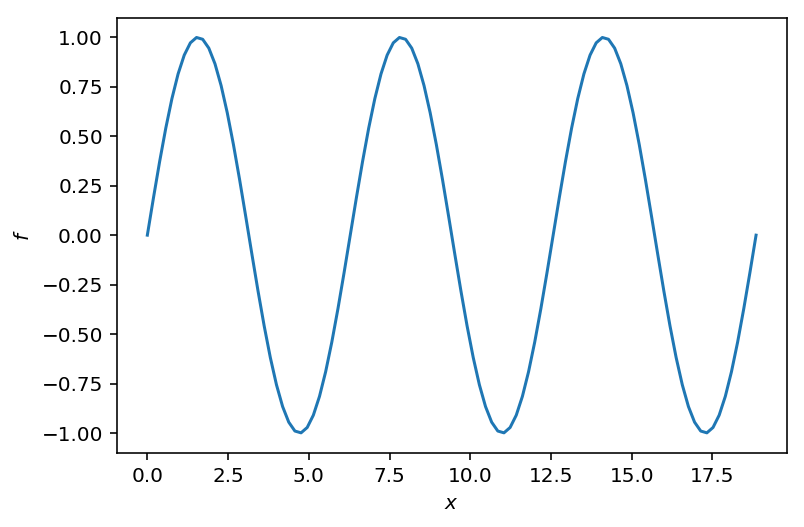

In [3]:
N = 100
x = np.linspace(0,6*np.pi,100)
f = np.sin(x)

# standard matplotlib figure
fig, ax = plt.subplots()
ax.plot(x,f)
ax.set_xlabel('$x$')
ax.set_ylabel('$f$');

## Plot using Bokeh

In [4]:
p = figure(width=800, height=400, tools=TOOLS, title=None)
p.line(x, f, line_width=2)
p.circle(x, f, fill_color='white',size=8)
p.xaxis.axis_label = 'x'
p.yaxis.axis_label = 'f=sin(x)'
show(p)

## Now let's estimate the derivative of $f$ using forward difference

### Using for loops

In [6]:
# using forward difference (loop)

df_f1 = np.zeros(N)

for i in range(0,N-1):
    df_f1[i]=   (f[i+1]-f[i])/(x[i+1]-x[i])

In [10]:
# what about that last point? Recall that the last point can be accessed as [-1]
df_f1[-1]

0.0

In [31]:
# let's use backwards difference for that point

df_f1[-1]=(f[-1]-f[-2])/(x[-1]-x[-2])
df_f1[-1] 

0.9939689438662982

In [32]:
df_f1

array([ 0.99396894,  0.95804432,  0.88749347,  0.7848663 ,  0.65387202,
        0.49924509,  0.32657415,  0.14209997, -0.04751008, -0.23540298,
       -0.41478781, -0.57918113, -0.72264133, -0.8399834 , -0.92696627,
       -0.98044617, -0.99849018, -0.98044617, -0.92696627, -0.8399834 ,
       -0.72264133, -0.57918113, -0.41478781, -0.23540298, -0.04751008,
        0.14209997,  0.32657415,  0.49924509,  0.65387202,  0.7848663 ,
        0.88749347,  0.95804432,  0.99396894,  0.99396894,  0.95804432,
        0.88749347,  0.7848663 ,  0.65387202,  0.49924509,  0.32657415,
        0.14209997, -0.04751008, -0.23540298, -0.41478781, -0.57918113,
       -0.72264133, -0.8399834 , -0.92696627, -0.98044617, -0.99849018,
       -0.98044617, -0.92696627, -0.8399834 , -0.72264133, -0.57918113,
       -0.41478781, -0.23540298, -0.04751008,  0.14209997,  0.32657415,
        0.49924509,  0.65387202,  0.7848663 ,  0.88749347,  0.95804432,
        0.99396894,  0.99396894,  0.95804432,  0.88749347,  0.78

In [34]:
# note that we could have written

ilast = N-1
df_f1[ilast]=(f[ilast]-f[ilast-1])/(x[ilast]-x[ilast-1])
df_f1[ilast]

0.9939689438662982

### Using vector operations and array slicing

In [45]:
f1 = np.arange(0,10,0.7)
f1

array([0. , 0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4,
       9.1, 9.8])

In [46]:
f1[1:]

array([0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4, 9.1,
       9.8])

In [47]:
f1[:-1]

array([0. , 0.7, 1.4, 2.1, 2.8, 3.5, 4.2, 4.9, 5.6, 6.3, 7. , 7.7, 8.4,
       9.1])

In [48]:
f1[1:]-f1[:-1]

array([0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7,
       0.7])

In [56]:
# we can also perform a forward difference using vector operations and array slicing

df_f2 = np.zeros(N)

df_f2[:-1] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
df_f2[-1] =(f[-1]-f[-2])/(x[-1]-x[-2])

### Now let's plot our FD differences against the analytic solution

In [57]:
p = figure(width=800, height=400, tools=TOOLS, title=None)
p.circle(x, df_f1,color="blue", alpha=0.5, size=8, legend_label="df/dx loop")
p.circle(x, df_f2, color="red", alpha=0.5, size=4, legend_label="df/dx array")
p.line(x, np.cos(x), line_width=2, color="black", legend_label="cos(x)")
p.xaxis.axis_label = 'x'
p.yaxis.axis_label = 'd[sin(x)]/dx, cos(x)'
show(p) 

## Estimate $df/dx$ with backward difference and central difference

In [63]:
df_f = np.zeros(N)
df_b = np.zeros(N)
df_c = np.zeros(N)

# forward difference
df_f[:-1] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
#df_f2[-1] = 

# backward difference
df_b[1:] = (f[1:]-f[:-1])/(x[1:]-x[:-1])
#df_b[0] = 

# # centeral difference
# # df_c[0] 
df_c[1:-1] = (f[2:]-f[:-2])/(x[2:]-x[:-2])
# # df_c[-1]

In [64]:
# plot the results
p = figure(width=800, height=400, tools=TOOLS, title=None)
p.circle(x, df_f,color="blue", alpha=0.5, size=8, legend_label="Forward")
p.circle(x, df_b, color="red", alpha=0.5, size=8, legend_label="Backward")
p.asterisk(x, df_c, color="green", alpha=1, size=12, legend_label="Central")
p.line(x, np.cos(x), line_width=2, color="black", legend_label="cos(x)")
p.xaxis.axis_label = 'x'
p.yaxis.axis_label = 'd[sin(x)]/dx, cos(x)'
show(p) 